# Original group notebook (archived as-is). Data paths point to the team's private Google Drive; see the repository README to run the refactored code.

# We have a README file to explain all our main files.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

!pip install scikit-surprise
!pip install seaborn

!pip install "numpy<2"

# csv_path = "/content/drive/My Drive/9727group/filtered_games.csv"

# user_dataset = pd.read_csv(csv_path)
# print("listing name：", user_dataset.columns.tolist())
# print("the first 5 rows:")
# print(user_dataset.head())


# print("calcualting ratings:")
def assign_rating(row):
    if row['is_recommended'] and row['hours'] >= 25:
        return 5
    elif row['is_recommended'] and row['hours'] >= 10:
        return 4
    elif row['is_recommended']:
        return 3
    elif row['hours'] >= 5:
        return 2
    else:
        return 1

# user_counts = user_dataset['user_id'].value_counts()
# item_counts = user_dataset['app_id'].value_counts()

# from tqdm import tqdm
# tqdm.pandas()
# user_dataset['rating'] = user_dataset.progress_apply(assign_rating, axis=1)
# user_dataset.to_csv("/content/drive/My Drive/9727group/filtered_games_with_rating.csv", index=False)



Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 3.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl size=2457387 sha256=055f247f9a68245dff36f88c064234a78b79679fcf518f878ae55142fa4c61cd
  Stored in directory: /root/.cache/pip/wheels/2a/8f/6e/7e2899163e2d85d8266daab4aa1cdabec7a6c56f83c015b5af
Successfully built scikit-surprise
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 96.2 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is th

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
    app_id  is_recommended  hours   user_id  \
0  1196590             1.0   19.0   5935019   
1   435150             1.0  199.9   6334645   
2   275850             1.0   13.6   6484333   
3   105600             1.0  911.8  10383001   
4  1794680             1.0   77.3  11659871   

                                  genre  rating  
0                                Action       4  
1                Adventure,RPG,Strategy       5  
2                      Action,Adventure       4  
3            Action,Adventure,Indie,RPG       5  
4  Action,Casual,Indie,RPG,Early Access       5  
Unique app id count: 3654


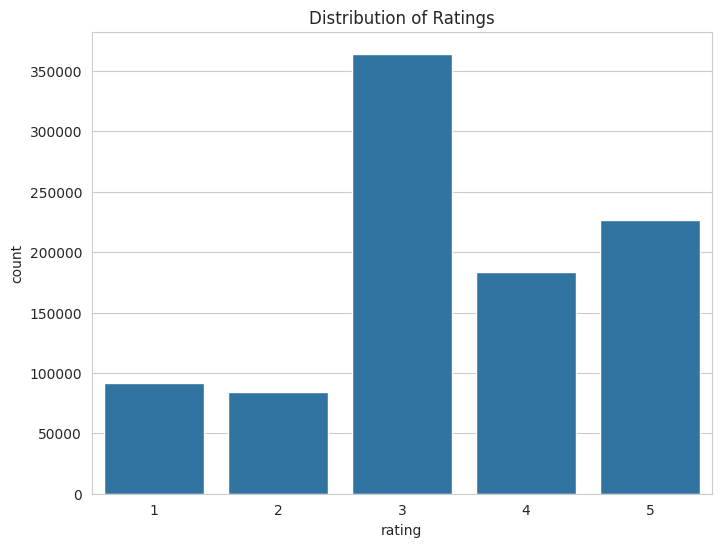

In [ ]:
from tqdm import tqdm
from google.colab import drive
drive.mount('/content/drive')
csv_path = "/content/drive/My Drive/9727group/filtered_games_with_rating.csv"
user_dataset = pd.read_csv(csv_path)
print(user_dataset.head())

unique_game_count = user_dataset['app_id'].nunique()
print("Unique app id count:", unique_game_count)


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize=(8,6))
sns.countplot(x='rating', data=user_dataset)
plt.title('Distribution of Ratings')
plt.show()

In [ ]:
from surprise import SVD
from surprise import Dataset, Reader
from sklearn.model_selection import train_test_split
import random
import pandas as pd
from tqdm import tqdm
tqdm.pandas()  # Let pandas DataFrames show a nice progress bar when using apply()
RANDOM_STATE = 42
random.seed(RANDOM_STATE)

def assign_rating(row):
    if row['is_recommended'] and row['hours'] >= 25:
        return 5
    elif row['is_recommended'] and row['hours'] >= 10:
        return 4
    elif row['is_recommended']:
        return 3
    elif row['hours'] >= 5:
        return 2
    else:
        return 1

# Path to the CSV containing sports game data
# sport_dataset = pd.read_csv(sport_csv_path)
# sport_dataset['rating'] = sport_dataset.progress_apply(assign_rating, axis=1)
sport_csv_path = "/content/drive/My Drive/9727group/user_sport.csv"
sport_dataset = pd.read_csv(sport_csv_path, encoding='ISO-8859-1')
sport_dataset['rating'] = sport_dataset.progress_apply(assign_rating, axis=1)
print(sport_dataset.head())

# Path to the CSV containing FPS game data
fps_csv_path = "/content/drive/My Drive/9727group/user_call_of_duty.csv"
fps_dataset = pd.read_csv(fps_csv_path,  encoding='ISO-8859-1')
fps_dataset['rating'] = fps_dataset.progress_apply(assign_rating, axis=1)
print(fps_dataset.head())

# Make sure all IDs are strings (avoids type mismatches later)
sport_dataset['user_id'] = sport_dataset['user_id'].astype(str)
sport_dataset['app_id'] = sport_dataset['app_id'].astype(str)
fps_dataset['user_id'] = fps_dataset['user_id'].astype(str)
fps_dataset['app_id'] = fps_dataset['app_id'].astype(str)
user_dataset['user_id'] = user_dataset['user_id'].astype(str)
user_dataset['app_id'] = user_dataset['app_id'].astype(str)

# Grab only the essential columns for model training
sport_data_filtered = sport_dataset[['user_id', 'app_id', 'rating']].copy()
fps_data_filtered = fps_dataset[['user_id', 'app_id', 'rating']].copy()

print(sport_data_filtered.head())
print(fps_data_filtered.head())

train_rows = []
test_rows = []

# Split each user's data into train/test so every user is represented in both sets
for uid, group in user_dataset.groupby('user_id'):
      train_part, test_part = train_test_split(group, test_size=0.2, random_state=RANDOM_STATE)
      train_rows.append(train_part)
      test_rows.append(test_part)

pre_train_df = pd.concat(train_rows)
test_df = pd.concat(test_rows)

# Merge multiple data sources if needed
# train_df = pd.concat([pre_train_df, sport_data_filtered, fps_data_filtered], ignore_index=True)
train_df = pre_train_df

unique_test_games = test_df['app_id'].nunique()

reader = Reader(rating_scale=(1,5))
train_data = Dataset.load_from_df(train_df[['user_id', 'app_id', 'rating']], reader)
trainset = train_data.build_full_trainset()

testset = list(test_df[['user_id', 'app_id', 'rating']].itertuples(index=False, name=None))

from surprise import SVD
from surprise.model_selection import GridSearchCV
param_grid = {
    'n_factors': [100],
    'reg_all': [0.02]
}

# Run a quick grid search to see if these params work well
gs = GridSearchCV(SVD, param_grid, measures=['rmse'], cv=3)
gs.fit(train_data)

# Show the best RMSE score and its parameters
print("Best RMSE score attained: ", gs.best_score['rmse'])
print("Best parameters: ", gs.best_params['rmse'])

# Train the best model we found on the full trainset
best_algo = gs.best_estimator['rmse']
best_algo.fit(trainset)

# Evaluate it on the test set
predictions = best_algo.test(testset)

for pred in predictions[:5]:
    print(pred)


100%|██████████| 18/18 [00:00<00:00, 11466.81it/s]


    app_id  is_recommended       hours   user_id  \
0   960170               1  137.693657  22222222   
1   207140               1    9.420437  22222222   
2   681280               0   95.964967  22222222   
3  1506830               1  113.220339  22222222   
4   212480               1  139.873221  22222222   

                               genre  \
0               Action,Casual,Sports   
1  Action,Casual,Indie,Racing,Sports   
2               Action,Racing,Sports   
3                  Simulation,Sports   
4                      Racing,Sports   

                                      About the game  \
0  DJMAX RESPECT V delivers an unrivaled rhythm g...   
1  In a city filled with superheroes, getting to ...   
2  From the developers of Action Henk , Descender...   
3  Powered by Football?, EA SPORTS? FIFA 22 bring...   
4  Sonic and the All-Stars cast line up on the st...   

                                                Tags  \
0  Rhythm,Casual,Action,Music,Sports,Great Soundt... 

100%|██████████| 24/24 [00:00<00:00, 11581.14it/s]


    app_id  is_recommended      hours   user_id             genre  \
0   311210               1  48.511753  11111111  Action,Adventure   
1  1238880               1  79.786204  11111111            Action   
2  1938090               1  72.481927  11111111            Action   
3   202970               1   5.701436  11111111            Action   
4    42700               1  82.550724  11111111            Action   

                                      About the game  \
0  Call of Duty?: Black Ops III Zombies Chronicle...   
1  Strategy. Speed. Story. These are the core pil...   
2  Existing Modern Warfare? II Digital Standard E...   
3  Pushing the boundaries of what fans have come ...   
4  The biggest first-person action series of all ...   

                                                Tags  \
0  Multiplayer,FPS,Zombies,Shooter,Action,First-P...   
1  Action,Multiplayer,Singleplayer,Shooter,FPS,Wa...   
2  FPS,Action,Multiplayer,Shooter,Military,First-...   
3  Action,Multiplayer,FP

In [ ]:
from surprise import accuracy

accuracy.rmse(predictions)

RMSE: 1.0428


1.0428022684292402

In [ ]:
import pandas as pd

# Get the set of target users (sports + FPS players), all as strings
target_users = set(sport_dataset['user_id'].astype(str)) | set(fps_dataset['user_id'].astype(str))

# Make sure both user_id and app_id are stored as strings (avoids matching issues)
train_df['user_id'] = train_df['user_id'].astype(str)
train_df['app_id'] = train_df['app_id'].astype(str)

# All unique game IDs that appear in the training data
all_game_ids = train_df['app_id'].unique()

top_500_records = []

for user_id in target_users:
    # Games this user has already played
    user_played = train_df[train_df['user_id'] == user_id]['app_id'].unique()
    candidate_games = [gid for gid in all_game_ids if gid not in user_played]

    # Build a temporary test set for this user
    user_testset = [(user_id, app_id, 0) for app_id in candidate_games]

    # Predict scores for each candidate
    predictions = best_algo.test(user_testset)

    # Keep only the top 500 highest-scoring games
    top_n = sorted(predictions, key=lambda x: x.est, reverse=True)[:500]

    for pred in top_n:
        top_500_records.append({
            'user_id': pred.uid,
            'app_id': pred.iid,
            'predicted_rating': pred.est
        })

# Save the results to CSV
top_500_df = pd.DataFrame(top_500_records)
top_500_df.to_csv('/content/drive/My Drive/9727group/top500_predictions_for_sport_fps_users.csv', index=False)
print("Top 500 recommendations generated for sport and FPS users only")


✅ Top 500 recommendations generated for sport and FPS users only


In [ ]:
def get_top_n_recommendations(predictions, n=10):
    top_n = {}

    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

top_n = get_top_n_recommendations(predictions, n=10)

for uid, user_ratings in list(top_n.items())[:3]:
    print(f"Top 10 recommendations for user {uid}: {', '.join([str(iid) for iid, _ in user_ratings])}")


def get_top_n_recommendations_with_scores(predictions, n=10):
    top_n = {}
    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

top_n = get_top_n_recommendations_with_scores(predictions, n=10)

for uid, user_ratings in list(top_n.items())[:5]:
    print(f"Top 10 recommendations for user {uid}:")
    for iid, est in user_ratings:
        print(f"    Game ID: {iid} | Predicted Score: {est:.3f}")


Top 10 recommendations for user 22222222: 2058180, 1235140, 435150, 294100, 1009850, 1454400, 105600, 1687950, 2058190, 927380
Top 10 recommendations for user 22222222:
    Game ID: 2058180 | Predicted Score: 4.638
    Game ID: 1235140 | Predicted Score: 4.618
    Game ID: 435150 | Predicted Score: 4.610
    Game ID: 294100 | Predicted Score: 4.609
    Game ID: 1009850 | Predicted Score: 4.585
    Game ID: 1454400 | Predicted Score: 4.582
    Game ID: 105600 | Predicted Score: 4.569
    Game ID: 1687950 | Predicted Score: 4.555
    Game ID: 2058190 | Predicted Score: 4.526
    Game ID: 927380 | Predicted Score: 4.512


In [ ]:
from collections import defaultdict

def get_top_n(predictions, n=10):
    # Build a ranked list of recommendations for each user
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        top_n[uid].append((iid, est))

    # Keep only the top-N items with the highest predicted scores for each user
    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = [iid for (iid, _) in user_ratings[:n]]
    return top_n

def precision_recall_at_k(top_n, ground_truth, k=10):
    precisions = []
    recalls = []

    for uid in top_n:
        pred_set = set(top_n[uid])
        true_set = set(ground_truth[uid])

        if not true_set:
            continue

        hit = len(pred_set & true_set)
        precisions.append(hit / k)
        recalls.append(hit / len(true_set))

    # Avoid division by zero if no users have ground truth data
    if not precisions:
        return 0.0, 0.0

    avg_precision = sum(precisions) / len(precisions)
    avg_recall = sum(recalls) / len(recalls)
    return avg_precision, avg_recall


# Build ground truth: items each user actually liked (e.g., rating ≥ 3)
ground_truth = defaultdict(list)
for uid, iid, true_r, est, _ in predictions:
    if true_r >= 3.0:
        ground_truth[uid].append(iid)

# Generate the top-K recommendation lists
top_n = get_top_n(predictions, n=10)

# Calculate Precision@10 and Recall@10
precision, recall = precision_recall_at_k(top_n, ground_truth, k=10)
print(f'Precision@10: {precision:.4f}')
print(f'Recall@10: {recall:.4f}')


Precision@10: 0.0000
Recall@10: 0.0000


In [ ]:
import numpy as np

def get_top_n_recommendations_with_scores(predictions, n=10):
    # Collect all predictions per user
    top_n = {}
    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    # Sort each user's predictions by score (highest first) and keep top-N
    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

# Get all users and items from the training set (internal Surprise IDs)
all_user_ids = trainset.all_users()
all_item_ids = trainset.all_items()

# Map internal IDs back to the original raw IDs
all_user_raw_ids = [trainset.to_raw_uid(uid) for uid in all_user_ids]
all_item_raw_ids = [trainset.to_raw_iid(iid) for iid in all_item_ids]

# Randomly sample 100 users for evaluation
sample_user_ids = random.sample(all_user_raw_ids, 100)

anti_testset = []
for uid in sample_user_ids:
    # Items the user has already interacted with
    user_interacted_items = set(j for (j, _) in trainset.ur[trainset.to_inner_uid(uid)])
    # Add all unseen items for this user into the anti-testset
    for iid in all_item_raw_ids:
        if trainset.to_inner_iid(iid) not in user_interacted_items:
            anti_testset.append((uid, iid, 0))  # Assign a placeholder rating of 0

# Run predictions for the anti-testset
predictions = best_algo.test(anti_testset)

# Extract the top-N recommendations with their scores
top_n = get_top_n_recommendations_with_scores(predictions, n=10)

# Show recommendations for the first 5 sampled users
for uid, user_ratings in list(top_n.items())[:5]:
    print(f"Top 10 recommendations for user {uid}:")
    for iid, est in user_ratings:
        print(f"    Game ID: {iid} | Predicted Score: {est:.3f}")


Top 10 recommendations for user 11939158:
    Game ID: 1151640 | Predicted Score: 5.000
    Game ID: 1454400 | Predicted Score: 5.000
    Game ID: 108600 | Predicted Score: 5.000
    Game ID: 431960 | Predicted Score: 5.000
    Game ID: 1145360 | Predicted Score: 5.000
    Game ID: 211820 | Predicted Score: 5.000
    Game ID: 294100 | Predicted Score: 5.000
    Game ID: 429660 | Predicted Score: 5.000
    Game ID: 292030 | Predicted Score: 4.993
    Game ID: 1009850 | Predicted Score: 4.922
Top 10 recommendations for user 10745402:
    Game ID: 489830 | Predicted Score: 5.000
    Game ID: 208650 | Predicted Score: 5.000
    Game ID: 1245620 | Predicted Score: 5.000
    Game ID: 526870 | Predicted Score: 5.000
    Game ID: 534380 | Predicted Score: 5.000
    Game ID: 812140 | Predicted Score: 5.000
    Game ID: 560130 | Predicted Score: 4.979
    Game ID: 1551360 | Predicted Score: 4.969
    Game ID: 397540 | Predicted Score: 4.966
    Game ID: 646570 | Predicted Score: 4.953
Top 10 rec

In [ ]:
def get_bottom_n_recommendations_with_scores(predictions, n=10):
    # Collect all predictions per user
    bottom_n = {}
    for uid, iid, true_r, est, _ in predictions:
        bottom_n.setdefault(uid, []).append((iid, est))

    # Sort from lowest to highest score and keep bottom-N
    for uid, user_ratings in bottom_n.items():
        user_ratings.sort(key=lambda x: x[1])
        bottom_n[uid] = user_ratings[:n]

    return bottom_n

# Get the lowest-scoring predictions for each user
bottom_n = get_bottom_n_recommendations_with_scores(predictions, n=10)

# Display bottom-N results for the first few users
for uid, user_ratings in list(bottom_n.items())[:5]:
    print(f"Bottom 10 predicted scores for user {uid}:")
    for iid, est in user_ratings:
        print(f"    Game ID: {iid} | Predicted Score: {est:.3f}")


Bottom 10 predicted scores for user 11939158:
    Game ID: 292630 | Predicted Score: 1.302
    Game ID: 542340 | Predicted Score: 1.564
    Game ID: 348510 | Predicted Score: 1.666
    Game ID: 201510 | Predicted Score: 1.667
    Game ID: 1517290 | Predicted Score: 1.714
    Game ID: 271500 | Predicted Score: 1.725
    Game ID: 409510 | Predicted Score: 1.833
    Game ID: 298240 | Predicted Score: 1.837
    Game ID: 1180320 | Predicted Score: 1.895
    Game ID: 1236300 | Predicted Score: 1.924
Bottom 10 predicted scores for user 10745402:
    Game ID: 1180320 | Predicted Score: 1.365
    Game ID: 201510 | Predicted Score: 1.458
    Game ID: 368990 | Predicted Score: 1.815
    Game ID: 409510 | Predicted Score: 1.862
    Game ID: 1184160 | Predicted Score: 1.917
    Game ID: 251950 | Predicted Score: 1.931
    Game ID: 950670 | Predicted Score: 1.980
    Game ID: 292630 | Predicted Score: 1.990
    Game ID: 348510 | Predicted Score: 2.062
    Game ID: 271500 | Predicted Score: 2.073
Bot

In [ ]:
from collections import defaultdict

def get_top_n(predictions, n=10):
    # Build a ranked list of recommendations for each user
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        top_n[uid].append((iid, est))

    # Keep only the top-N items with the highest predicted scores for each user
    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = [iid for (iid, _) in user_ratings[:n]]
    return top_n

def precision_recall_at_k(top_n, ground_truth, k=10):
    precisions = []
    recalls = []

    for uid in top_n:
        pred_set = set(top_n[uid])
        true_set = set(ground_truth[uid])

        if not true_set:
            continue

        hit = len(pred_set & true_set)
        precisions.append(hit / k)
        recalls.append(hit / len(true_set))

    avg_precision = sum(precisions) / len(precisions)
    avg_recall = sum(recalls) / len(recalls)
    return avg_precision, avg_recall

ground_truth = defaultdict(set)
# Build ground truth: items each user actually liked (e.g., rating ≥ 3)
for row in test_df.itertuples(index=False):
    uid, iid, rating = row.user_id, row.app_id, row.rating
    if rating >= 3.0:
        ground_truth[uid].add(iid)

# Generate the top-K recommendation lists
top_n = get_top_n(predictions, n=10)

# Calculate Precision@10 and Recall@10
precision, recall = precision_recall_at_k(top_n, ground_truth, k=10)
print(f'Precision@10: {precision:.4f}')
print(f'Recall@10: {recall:.4f}')


Precision@10: 0.0230
Recall@10: 0.0112
